# Fig. 5e: curation of the "good" units (spontaneous regime)

**author**: laquitainesteeve@gmail.com

**purpose**: precision and recall of the model that curates the "good" units amongst the sorted single-units of Kilosort 4, for the biophysical simulation in the spontaneous regime.

In [1]:
# automatically reload notebook
%load_ext autoreload
%autoreload 2

# import built-in packages
import os

# limit BLAS/OpenMP threads per worker, BEFORE numpy is imported
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "1"
    
import shutil
import pickle
import copy
import random
import pandas as pd
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.core.template_tools as ttools
from spikeinterface import comparison
from spikeinterface.curation import remove_excess_spikes
from spikeinterface import extract_waveforms
from spikeinterface.postprocessing import compute_principal_components
from spikeinterface.qualitymetrics import compute_quality_metrics as qm
import statsmodels.api as sm
from statsmodels.tools.validation import float_like
import torch
import numpy as np
from matplotlib import pyplot as plt
import sklearn
import seaborn as sns
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
import warnings
import spikecurate 

# silence irrelevant warnings
warnings.filterwarnings("ignore", message="There is no Probe attached to this recording.*")
warnings.filterwarnings("ignore", message="Versions are not the same.*")

# spikeinterface version
print("Spikeinterface", si.__version__)

# set project path
proj_path = "/home/steeve/steeve/epfl/code/spikebias-paper/"
os.chdir(proj_path)
os.environ["PYTHONPATH"] = proj_path     # worker processes must be able to import the project

# import custom package
from src.nodes.models.Flc import dataloader

# experiment parameters
EXP = "NS"
SORTER = "KS4"

# waveform extraction parameters
FREQ_MIN = 300
REFERENCE = "global"
OPERATOR = "median"
MS_BEFORE = 6
MS_AFTER = 6
SAVE_SOURCE_DATA = False
LOAD_WE = True              # reuse the stored waveforms and PCA when they exist
DURATION_SEC = 600          # 10 minutes recording
MAX_SPIKES_PER_UNIT = 500   # max number of spikes used per unit
SEED = 0
N_COMP_PCA = 5              # number of pca components
SPARSE = True
OVERWRITE = True
WE_JOB_KWARGS = dict(n_jobs=20, chunk_duration="1s", progress_bar=True)
job_kwargs = dict(n_jobs=-1, progress_bar=True)

CHUNKS = 80000 # for waveform extractor

# model parameters
model_prms = {"seeds": np.arange(0,100,1), "scale_data": False}

# recording extractor
RECORDING_PATH = "dataset/00_raw/recording_npx_spont/"

# kilosort sorting extractor
SORTING_KS4_PATH = "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m/"

# ground truth extractors
SORTING_TRUE = "dataset/00_raw/ground_truth_npx_spont"
SORTING_TRUE_10mn = "dataset/00_raw/ground_truth_npx_spont_10m"

# waveform extractors
WE_SINGLE_U_PATH = "dataset/01_intermediate/waveforms/npx_spont/SortingKS4_10m_single_units"

# unit classification
QUALITY_PATH = "dataset/01_intermediate/analysis/sorting_quality/sorting_quality.csv"

# figure parameters
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5 # typically between 0.5 and 1
plt.rcParams["axes.linewidth"] = 0.5 
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1

# figure legend parameters
legend_cfg = {"frameon": False, "handletextpad": 0.5}
tight_layout_cfg = {"pad": 0.001}
LG_FRAMEON = False              # no legend frame

Spikeinterface 0.100.8


In [2]:
import os, sys
sys.path.insert(0, os.getcwd())     # the repository
from src.nodes import figure_style
figure_style.apply()

## Load datasets

* Execution time: 27 ms

### Recording extractor

* Execution time: 

In [3]:
%%time

# load and preprocess recording
Recording = si.load_extractor(RECORDING_PATH)
Recording.set_property('location', Recording.get_property('location')[:,:2])
Recording = spre.highpass_filter(Recording, freq_min=FREQ_MIN)
Recording = spre.common_reference(Recording, reference=REFERENCE, operator=OPERATOR)
# keep the first 10 min so that the recording duration matches the sorting
Recording = Recording.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))
display(Recording)

FrameSliceRecording: 384 channels - 40.0kHz - 1 segments - 24,000,000 samples 
                     600.00s (10.00 minutes) - float32 dtype - 34.33 GiB

CPU times: user 3.87 ms, sys: 0 ns, total: 3.87 ms
Wall time: 3.85 ms


### Ground truth extractor

* Execution time: 

In [4]:
%%time

# load ground truth
SortingTrue = si.load_extractor(SORTING_TRUE)
SortingTrue = SortingTrue.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))
SortingTrue.save(folder=SORTING_TRUE_10mn, overwrite=True)
display(SortingTrue)

FrameSliceSorting: 1388 units - 1 segments - 40.0kHz

CPU times: user 215 ms, sys: 9.93 ms, total: 225 ms
Wall time: 225 ms


### Sorting extractor

* Execution time: 20 ms

In [5]:
%%time

# load sorting
Sorting = si.load_extractor(SORTING_KS4_PATH)
Sorting = remove_excess_spikes(Sorting, Recording)
Sorting = Sorting.frame_slice(start_frame=0, end_frame=Recording.get_sampling_frequency() * DURATION_SEC)
display(Sorting)

FrameSliceSorting: 520 units - 1 segments - 40.0kHz

CPU times: user 1.19 ms, sys: 31 µs, total: 1.22 ms
Wall time: 1.2 ms


### Waveform extractor (Sorted units)

* Execution time: 2.5 min

In [6]:
%%time 

# select sorted single-units amongst single- and multi-units
single_unit_ids = Sorting.unit_ids[np.where(Sorting.get_property("KSLabel") == "good")[0]]
Sorting_single_units = Sorting.select_units(unit_ids=single_unit_ids)

# save their waveforms and their PCA, or load them from a previous run
if LOAD_WE and os.path.exists(WE_SINGLE_U_PATH):
    We_single_u = si.load_waveforms(WE_SINGLE_U_PATH)
else:
    We_single_u = extract_waveforms(Recording, Sorting_single_units, WE_SINGLE_U_PATH, mode="folder", sparse=SPARSE, ms_before=MS_BEFORE,
                        ms_after=MS_AFTER, max_spikes_per_unit=MAX_SPIKES_PER_UNIT, unit_batch_size=CHUNKS,
                        overwrite=OVERWRITE, seed=SEED, **WE_JOB_KWARGS)
    pca = compute_principal_components(waveform_extractor=We_single_u, n_components=N_COMP_PCA, mode="by_channel_local", **WE_JOB_KWARGS)

CPU times: user 9.91 ms, sys: 22 ms, total: 31.9 ms
Wall time: 31.9 ms


### Single-unit ids and labels (good/gad)

In [7]:
%%time

# label "good" and "bad" sorted single-units to train the classifier
good_unit_ids, bad_unit_ids = dataloader.get_good_and_bad_units(QUALITY_PATH, exp="NS", sorter="KS4")

# report
print("\nSingle-unit ids:", single_unit_ids)
print("\nGood unit ids:", good_unit_ids)
print("\nBad unit ids:", bad_unit_ids)


Single-unit ids: ['26' '29' '40' '41' '42' '45' '48' '53' '54' '55' '56' '58' '60' '61'
 '66' '71' '76' '77' '81' '83' '84' '85' '86' '90' '96' '102' '104' '105'
 '108' '109' '110' '113' '116' '117' '120' '121' '122' '126' '127' '128'
 '130' '135' '140' '142' '143' '146' '149' '152' '157' '158' '160' '162'
 '165' '166' '172' '183' '189' '193' '197' '198' '199' '201' '202' '207'
 '211' '213' '214' '221' '223' '227' '231' '239' '240' '241' '247' '249'
 '250' '252' '254' '262' '263' '264' '269' '270' '277' '280' '281' '283'
 '284' '286' '289' '291' '292' '296' '297' '299' '300' '302' '304' '307'
 '308' '310' '315' '316' '318' '319' '321' '323' '325' '328' '333' '339'
 '341' '342' '345' '346' '348' '350' '358' '365' '368' '371' '374' '380'
 '381' '384' '385' '386' '389' '390' '391' '393' '396' '398' '399' '400'
 '401' '402' '405' '408' '410' '411' '413' '420' '424' '426' '429' '432'
 '435' '438' '440' '442' '445' '446' '448' '449' '450' '451' '452' '453'
 '455' '458' '459' '460' '461' '46

### Unit-tests

In [8]:
%%time

# sanity check units are correct
single_unit_ids_from_file = dataloader.get_sorted_single_unit_ids_from_file(QUALITY_PATH, EXP, SORTER)
assert len(np.intersect1d(single_unit_ids_from_file, single_unit_ids)) == len(single_unit_ids_from_file), "Units are missing or differ"

CPU times: user 5.53 ms, sys: 0 ns, total: 5.53 ms
Wall time: 5.54 ms


## Engineer unit quality metrics

* Execution time: 2 min

In [9]:
%%time

# engineer a dataset of quality metrics per cell
data = spikecurate.load_dataset(single_unit_ids, good_unit_ids, bad_unit_ids, Sorting_single_units, SortingTrue, We_single_u, load_qm_if_exists=False, delta_time=1.3, job_kwargs=WE_JOB_KWARGS)

extract amplitudes:   0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/184 [00:00<?, ?it/s]

extract amplitudes:   0%|          | 0/600 [00:00<?, ?it/s]

CPU times: user 13.9 s, sys: 5.5 s, total: 19.4 s
Wall time: 1min 23s


In [10]:
%%time 

# measure correlations between features
data["dataset"].corr()

CPU times: user 142 µs, sys: 0 ns, total: 142 µs
Wall time: 144 µs


,amplitude_cutoff,firing_range,firing_rate,isi_violations_ratio,rp_contamination,rp_violations,sd_ratio,snr,silhouette,mad_ratio,quality_label
amplitude_cutoff,1.000000,-0.098425,-0.160869,0.291870,0.058167,-0.034757,0.458470,0.590338,0.368444,0.250986,-0.110314
firing_range,-0.098425,1.000000,0.577485,-0.047203,0.129424,0.423390,0.054357,-0.256360,-0.336816,0.223974,-0.378831
firing_rate,-0.160869,0.577485,1.000000,-0.080729,0.046400,0.429786,-0.118931,-0.208583,-0.241336,-0.005137,0.066000
isi_violations_ratio,0.291870,-0.047203,-0.080729,1.000000,0.558257,0.182912,0.224311,0.287665,0.171489,0.067216,0.023906
rp_contamination,0.058167,0.129424,0.046400,0.558257,1.000000,0.500537,0.103118,-0.001986,-0.030178,0.063686,-0.019728
rp_violations,-0.034757,0.423390,0.429786,0.182912,0.500537,1.000000,0.003533,-0.078441,-0.102563,0.015273,-0.043278
sd_ratio,0.458470,0.054357,-0.118931,0.224311,0.103118,0.003533,1.000000,0.438884,0.082939,0.873798,-0.291286
snr,0.590338,-0.256360,-0.208583,0.287665,-0.001986,-0.078441,0.438884,1.000000,0.548983,0.104839,0.217630
silhouette,0.368444,-0.336816,-0.241336,0.171489,-0.030178,-0.102563,0.082939,0.548983,1.000000,-0.124906,0.151507
mad_ratio,0.250986,0.223974,-0.005137,0.067216,0.063686,0.015273,0.873798,0.104839,-0.124906,1.000000,-0.439738


## Model: train/detect >80% accurate units

In [11]:
# dataset: 10 quality metrics
dataset = data["dataset"].replace([np.inf, -np.inf], np.nan).dropna()
print("units:", len(dataset), "of", len(data["dataset"]), "| good:", int(dataset["quality_label"].sum()))

units: 182 of 184 | good: 84


In [12]:
%%time

# the model: lasso-regularized binomial GLM on the 10 quality metrics
model = spikecurate.FractionalLogisticClassifier(data["predictors"], C=100)
results = model.crossval_evaluate(dataset, seeds=np.arange(0, 100, 1), scale_data=True)
stats_ = results["metric_stats"]
print(f"precision median {stats_['precision_median']:.3f} (95% CI {stats_['precision_ci95']:.3f}), recall median {stats_['recall_median']:.3f} (95% CI {stats_['recall_ci95']:.3f})")

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


precision median 0.867 (95% CI 0.018), recall median 0.615 (95% CI 0.020)
CPU times: user 14 s, sys: 0 ns, total: 14 s
Wall time: 14 s


## Source data

In [13]:
# source data: precision and recall of the model in each split
df = pd.DataFrame({"seed": np.arange(0, 100, 1), "precision": [m["precision"] for m in results["metric_data"]], "recall": [m["recall"] for m in results["metric_data"]]})
display(df[["precision", "recall"]].agg(["median", "count"]))

,precision,recall
median,0.866667,0.615079
count,100.000000,100.000000


In [14]:
from src.nodes.models.Flc import curation_plots as cp


def plot_source_data(df: pd.DataFrame):
    """Precision and recall of the model on the test units of each cross-validation fold"""
    return cp.plot_precision_recall(df, "e")

CPU times: user 10.1 ms, sys: 2.03 ms, total: 12.2 ms
Wall time: 12.2 ms


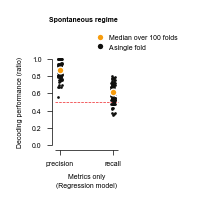

In [15]:
%%time

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

# plot
fig = plot_source_data(df)

# save figure
if SAVE_SOURCE_DATA:
    os.makedirs("figures/source_data/fig5e", exist_ok=True)
    fig.savefig("figures/source_data/fig5e/fig5e.svg", **savefig_cfg)

# save source data
if SAVE_SOURCE_DATA:
    df.to_excel("figures/source_data/fig5e/fig5e.xlsx", index=False)

CPU times: user 39.1 ms, sys: 3.02 ms, total: 42.2 ms
Wall time: 42.1 ms


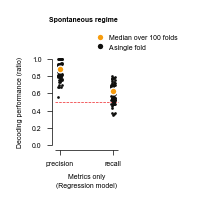

In [16]:
%%time

# check: replot from the saved source data
df = pd.read_excel("figures/source_data/fig5e/fig5e.xlsx")
fig = plot_source_data(df)

## Experiment: log-transformed features

In [17]:
%%time
from scipy import stats

# log-transform the features with a long-tailed distribution
dataset_log = dataset.copy()
for feature in ["firing_rate", "firing_range", "sd_ratio", "snr", "mad_ratio"]:
    dataset_log[feature] = np.log(dataset_log[feature].values)
    assert np.isfinite(dataset_log[feature]).all(), f"{feature} log-transform is not finite"  # unit-test

results_log = model.crossval_evaluate(dataset_log, seeds=np.arange(0, 100, 1), scale_data=True)
stats_ = results_log["metric_stats"]
print(f"log-transformed features: precision median {stats_['precision_median']:.3f} (95% CI {stats_['precision_ci95']:.3f}), recall median {stats_['recall_median']:.3f} (95% CI {stats_['recall_ci95']:.3f})")

# paired comparison with the raw features: two-sided corrected resampled t-test
k = len(results["metric_data"])
n_train = int(np.round(0.75 * len(dataset)))
n_test = len(dataset) - n_train
for metric in ["precision", "recall"]:
    diff = np.array([m[metric] for m in results_log["metric_data"]]) - np.array([m[metric] for m in results["metric_data"]])
    t = diff.mean() / np.sqrt((1 / k + n_test / n_train) * diff.var(ddof=1))
    p = 2 * stats.t.sf(abs(t), k - 1)
    print(f"{metric}: mean difference (log - raw) {diff.mean():+.3f}, corrected resampled t-test t({k - 1}) = {t:.2f}, P = {p:.2f}")

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


log-transformed features: precision median 0.882 (95% CI 0.015), recall median 0.636 (95% CI 0.022)
precision: mean difference (log - raw) +0.016, corrected resampled t-test t(99) = 0.49, P = 0.62
recall: mean difference (log - raw) +0.020, corrected resampled t-test t(99) = 0.48, P = 0.63
CPU times: user 6.36 s, sys: 1.7 ms, total: 6.36 s
Wall time: 6.36 s
